<a href="https://colab.research.google.com/github/xtianu/Docencia/blob/main/UPC/DAPR/S4.%20Flipped%20classroom/S4_FlippedClassroom_Exercises_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

**Student:** Arnau Guerrero Romero

**Group:** 11


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Missing values after cleaning:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

Shape after cleaning: (333, 7)
First 10 assigned labels: [0 0 0 0 0 0 0 0 0 0]


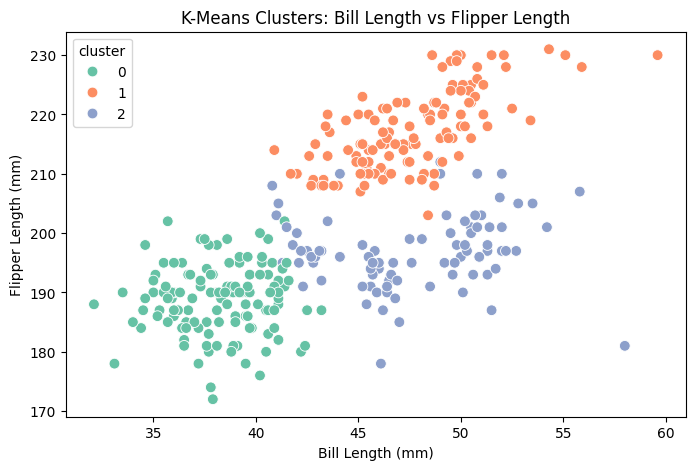

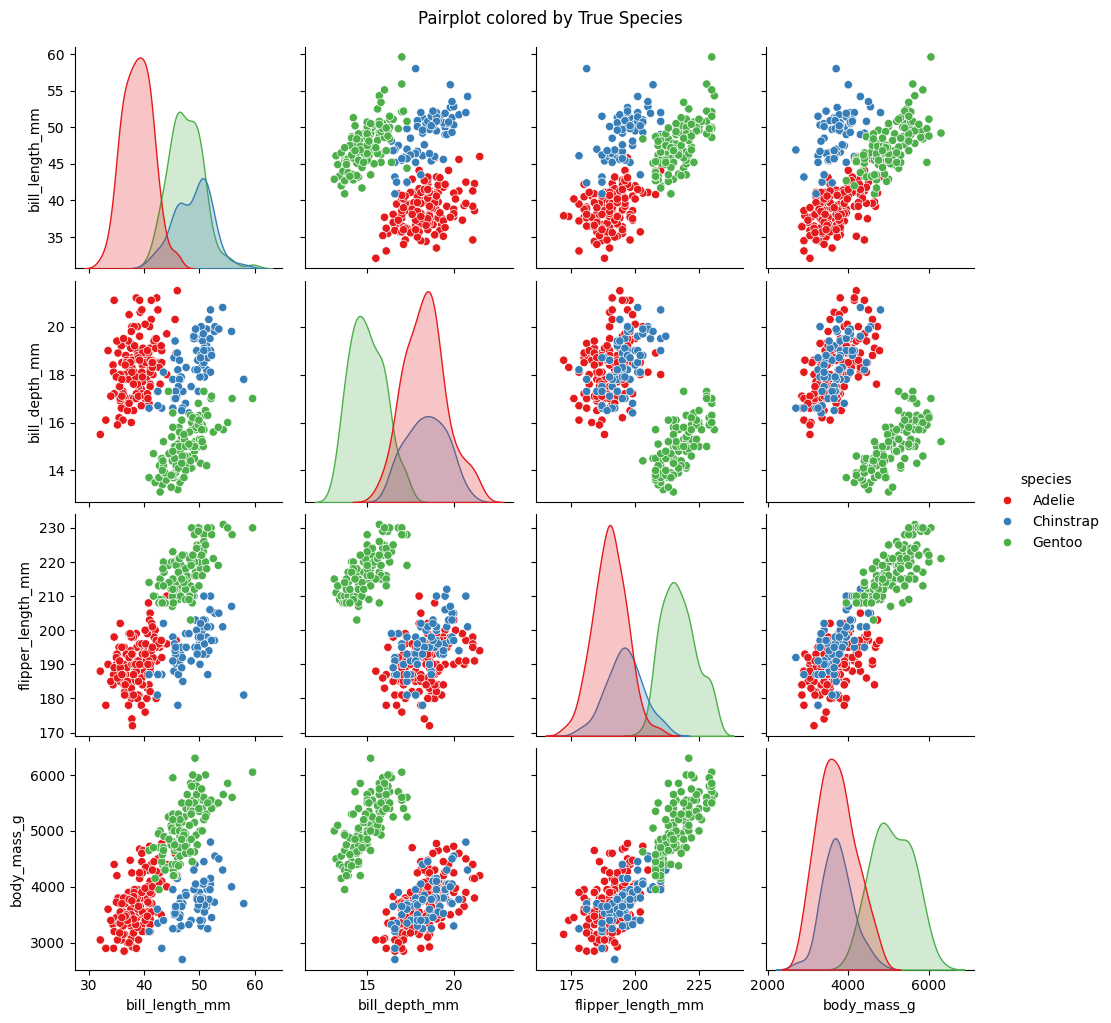

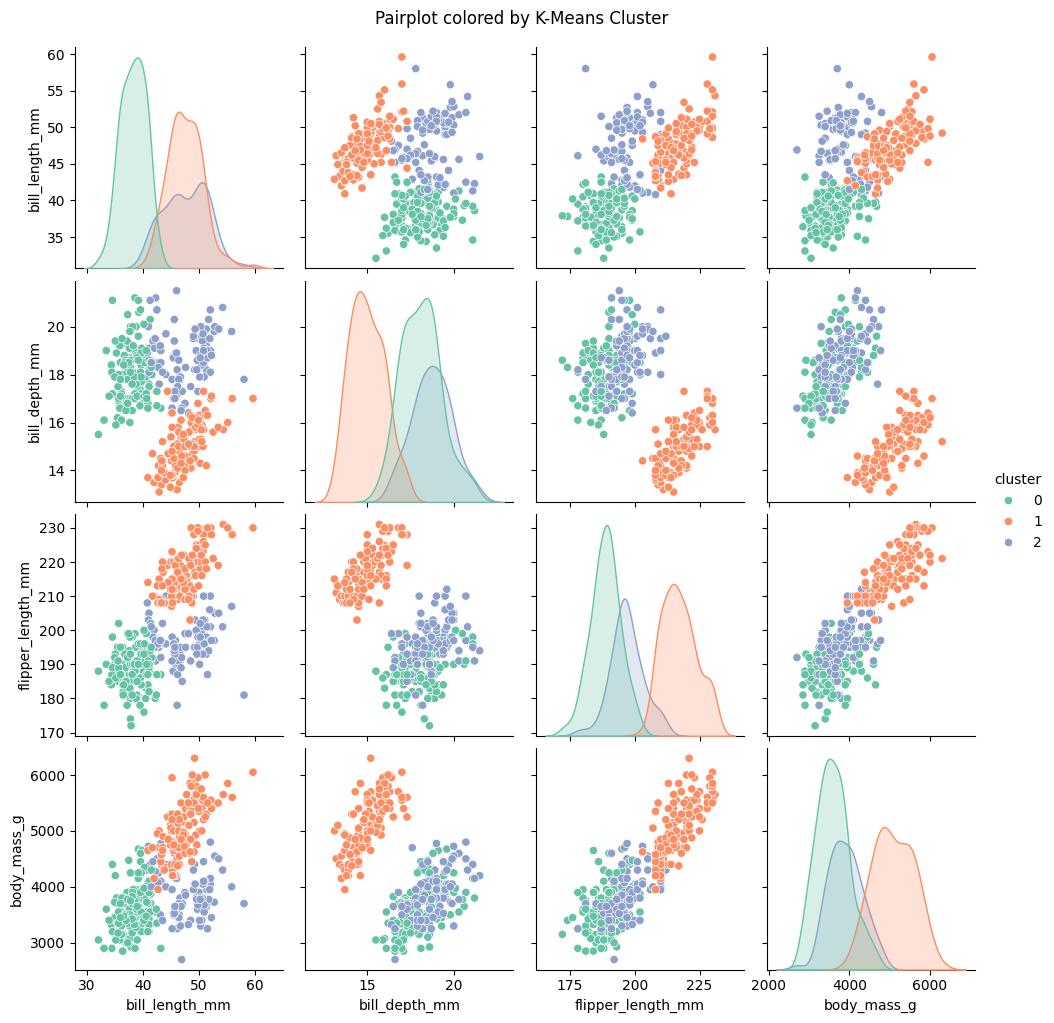

Confusion matrix:
 [[124   0  22]
 [  5   0  63]
 [  0 119   0]]
Adjusted rand score: 0.7994


In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
print("Missing values per column:")
print(penguins.isnull().sum())
penguins_clean = penguins.dropna().copy()
print("\nMissing values after cleaning:")
print(penguins_clean.isnull().sum())
print(f"\nShape after cleaning: {penguins_clean.shape}")

# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
num_cols = penguins_clean.select_dtypes(include=['float64', 'int64']).columns
scaler = StandardScaler()
scaled_data = scaler.fit_transform(penguins_clean[num_cols])
penguins_scaled_df = pd.DataFrame(
  scaled_data,
  columns = num_cols,
  index = penguins_clean.index
)
penguins_scaled_df.head()
# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(penguins_scaled_df)
print("First 10 assigned labels:", kmeans_labels[:10])

# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)
penguins_clean['cluster'] = kmeans_labels
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='cluster',
    palette='Set2',
    s=60
)
plt.title('K-Means Clusters: Bill Length vs Flipper Length')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.show()
sns.pairplot(
    data=penguins_clean,
    vars=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g'],
    hue='species',
    palette='Set1'
)
plt.suptitle('Pairplot colored by True Species', y=1.02)
plt.show()
sns.pairplot(
    data=penguins_clean,
    vars=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g'],
    hue='cluster',
    palette='Set2'
)
plt.suptitle('Pairplot colored by K-Means Cluster', y=1.02)
plt.show()
# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'
le = LabelEncoder()
species_encoded = le.fit_transform(penguins_clean['species'])

matrix_confusion = confusion_matrix(species_encoded, penguins_clean['cluster'])
rand_score = adjusted_rand_score(species_encoded, penguins_clean['cluster'])

print("Confusion matrix:\n", matrix_confusion)
print(f"Adjusted rand score: {rand_score:.4f}")
# f) YOUR CODE HERE (as a comment or markdown cell): interpretation


---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Are there any missing values in X?: False
Normalized X:
 [[-1.         -0.23354968]
 [-1.          0.70064905]
 [-1.         -1.16774842]
 [ 1.          1.63484778]
 [ 1.          0.23354968]
 [ 1.         -1.16774842]]
Manual distance: nan
NumPy distance:      5.656854249492381
Agglomerative labels: [1 1 1 0 0 0]


/tmp/ipykernel_2109/2055932518.py:22: RuntimeWarning: invalid value encountered in power
  return Squared_diff_sum ** 0.5


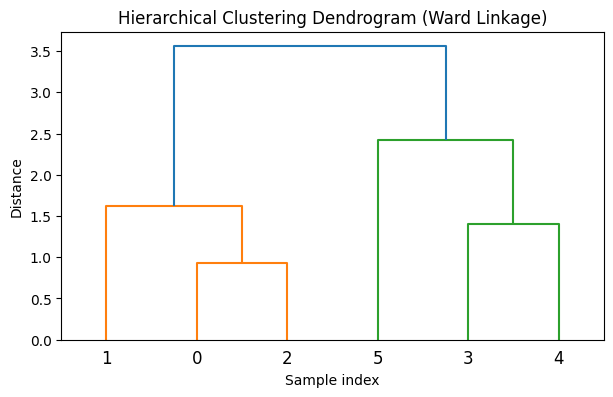

K-Means labels: [0 0 0 1 1 1]
Agglomerative labels: [1 1 1 0 0 0]
K-Means labels:       [0 0 0 1 1 1]
Agreement between both clusterings (ARI): 1.0000


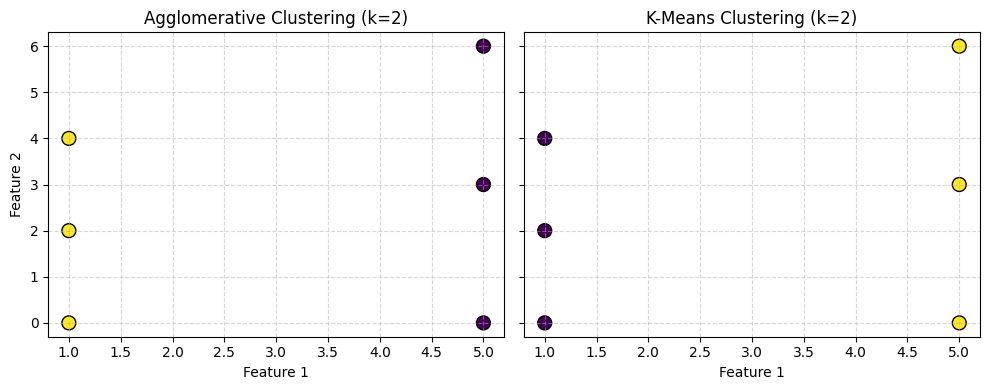

Agglomerative cluster sizes: {np.int64(1): 1, np.int64(0): 2}
K-Means cluster sizes:       {np.int32(0): 1, np.int32(1): 2}


In [ ]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
print("Are there any missing values in X?:", np.isnan(X).any())

# b) YOUR CODE HERE: normalize X with StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Normalized X:\n", X_scaled)

# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):
  Squared_diff_sum = 0
  for i in range(len(p1)):
    Squared_diff_sum += (p1[i] - p2[i] **2)
    return Squared_diff_sum ** 0.5

# test it
print("Manual distance:", euclidean_distance(X[0], X[3]))
print("NumPy distance:     ", np.linalg.norm(X[0] - X[3]))
# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
agglo = AgglomerativeClustering(n_clusters=2)
agglo_labels = agglo.fit_predict(X_scaled)
print("Agglomerative labels:", agglo_labels)
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(7, 4))
dendrogram(Z)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Sample index')
plt.ylabel('Distance')
plt.show()


# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
print("K-Means labels:", kmeans_labels)


# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
print("Agglomerative labels:", agglo_labels)
print("K-Means labels:      ", kmeans_labels)
ari_score = adjusted_rand_score(agglo_labels, kmeans_labels)
print(f"Agreement between both clusterings (ARI): {ari_score:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
scatter1 = axes[0].scatter(X[:, 0], X[:, 1], c=agglo_labels, cmap='viridis', s=100, edgecolors='k')
axes[0].set_title('Agglomerative Clustering (k=2)')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot K-Means clustering
scatter2 = axes[1].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', s=100, edgecolors='k')
axes[1].set_title('K-Means Clustering (k=2)')
axes[1].set_xlabel('Feature 1')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
# g) YOUR CODE HERE: cluster_sizes function using a dictionary
def cluster_sizes(labels):
  counts = {}
  for label in labels:
   if label not in counts:
      counts[label] = 1
  else:
       counts[label] += 1
  return counts
print("Agglomerative cluster sizes:", cluster_sizes(agglo_labels))
print("K-Means cluster sizes:      ", cluster_sizes(kmeans_labels))

---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Missing values before cleaning:
carat    0
depth    0
table    0
price    0
x        0
y        0
z        0
dtype: int64

Missing values after dropna():
carat    0
depth    0
table    0
price    0
x        0
y        0
z        0
dtype: int64

Any NaN left?: False
Final shape of diamonds_num: (1000, 7)


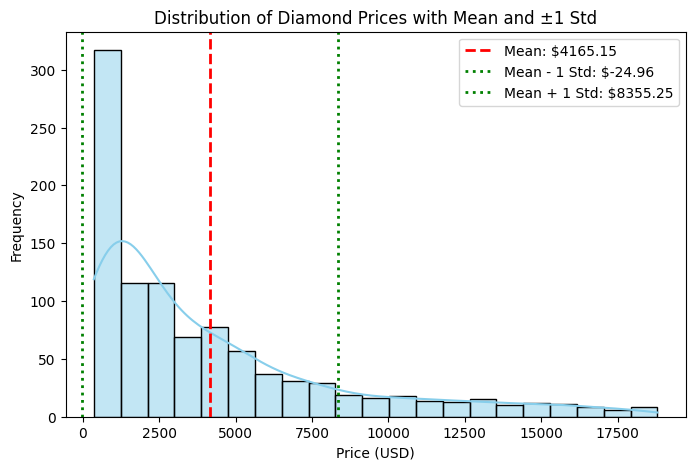

Shape de diamonds_scaled: (1000, 4)
Mean per column (scaled): [-0.  0. -0. -0.]
Standard deviation per column (scaled): [1. 1. 1. 1.]


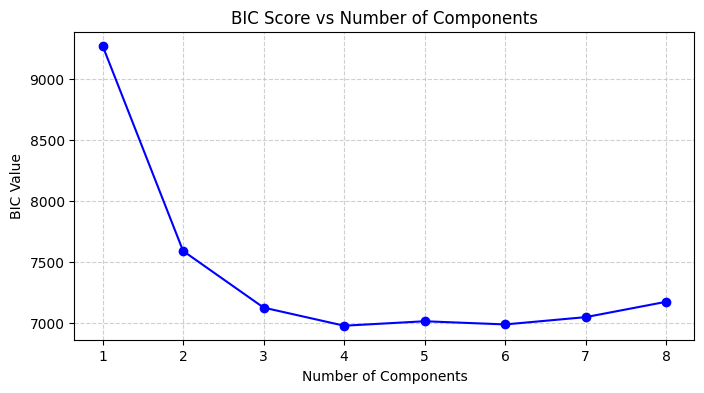

Optimal number of components (minimum BIC): 4
Number of components that minimizes BIC: 4
Predicted GMM cluster labels (first 10): [0 3 0 0 1 2 3 3 2 2]


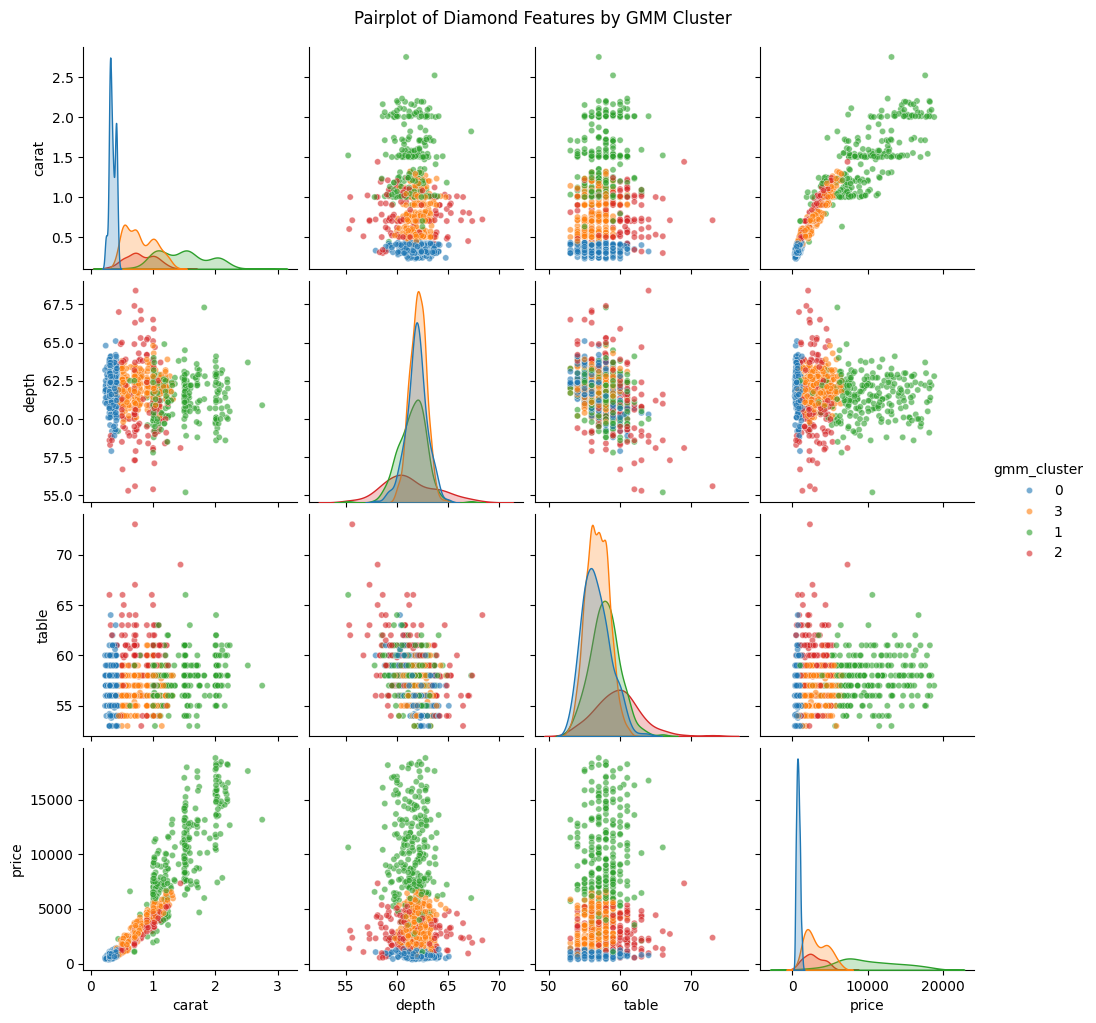

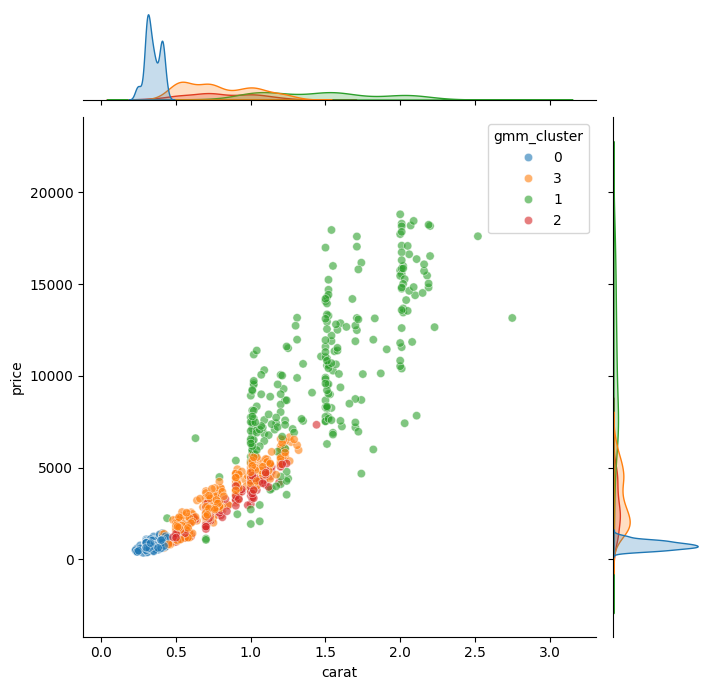

In [ ]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
diamonds_num = diamonds_num = diamonds.select_dtypes(include=[np.number]).copy()
print("Missing values before cleaning:")
print(diamonds_num.isna().sum())
diamonds_num = diamonds_num.dropna()
print("\nMissing values after dropna():")
print(diamonds_num.isna().sum())
print("\nAny NaN left?:", diamonds_num.isna().any().any())
print(f"Final shape of diamonds_num: {diamonds_num.shape}")
# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines
mean_price = diamonds_num['price'].mean()
std_price = diamonds_num['price'].std()
plt.figure(figsize=(8, 5))
sns.histplot(diamonds_num['price'], kde=True, color='skyblue', edgecolor='black')
plt.axvline(mean_price, color='red', linestyle='--', linewidth=2, label=f'Mean: ${mean_price:.2f}')
plt.axvline(mean_price - std_price, color='green', linestyle=':', linewidth=2, label=f'Mean - 1 Std: ${mean_price - std_price:.2f}')
plt.axvline(mean_price + std_price, color='green', linestyle=':', linewidth=2, label=f'Mean + 1 Std: ${mean_price + std_price:.2f}')
plt.title("Distribution of Diamond Prices with Mean and ±1 Std")
plt.xlabel("Price (USD)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
numeric_cols = ['carat', 'depth', 'table', 'price']
scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num[numeric_cols])
print("Shape de diamonds_scaled:", diamonds_scaled.shape)
print("Mean per column (scaled):", diamonds_scaled.mean(axis=0).round(2))
print("Standard deviation per column (scaled):", diamonds_scaled.std(axis=0).round(2))

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)
for k in n_components_range:
    gmm = mixture.GaussianMixture(n_components=k, random_state=42)
    gmm.fit(diamonds_scaled)
    bic.append(gmm.bic(diamonds_scaled))
plt.figure(figsize=(8, 4))
plt.plot(n_components_range, bic, marker='o', linestyle='-', color='b')
plt.title('BIC Score vs Number of Components')
plt.xlabel('Number of Components')
plt.ylabel('BIC Value')
plt.xticks(list(n_components_range))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
best_k = list(n_components_range)[bic.index(min(bic))]
print(f"Optimal number of components (minimum BIC): {best_k}")

# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
best_n = list(n_components_range)[np.argmin(bic)]
gmm_best = mixture.GaussianMixture(n_components=best_n, random_state=42)
gmm_labels = gmm_best.fit_predict(diamonds_scaled)
print(f"Number of components that minimizes BIC: {best_n}")
print("Predicted GMM cluster labels (first 10):", gmm_labels[:10])


# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
diamonds_num['gmm_cluster'] = gmm_labels.astype(str)
sns.pairplot(
    data=diamonds_num,
    vars=['carat', 'depth', 'table', 'price'],
    hue='gmm_cluster',
    palette='tab10',
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 's': 20}
)
plt.suptitle("Pairplot of Diamond Features by GMM Cluster", y=1.02)
plt.show()
sns.jointplot(
    data=diamonds_num,
    x='carat',
    y='price',
    hue='gmm_cluster',
    palette='tab10',
    alpha=0.6,
    height=7
)
plt.show()

# g) YOUR CODE HERE (as a comment or markdown cell): interpretation
# The BIC curve identifies an optimal number of clusters by balancing model fit with complexity, showing that the diamonds data is best described by distinct subpopulations rather than a single Gaussian distribution. The resulting clusters primarily segment diamonds across weight (carat) and value (price), capturing their non-linear exponential relationship and increasing price variance at higher carats, while geometric features like depth and table remain largely overlapping and centered across groups due to standardized cutting norms.
